# Capa de cuevas (v0) · Luna y Marte
**NASA Space Apps Challenge 2026** · El enunciado pide considerar "cuevas y otros entornos con condiciones similares".

**Por qué**: los tubos de lava de la Luna y de Marte protegen de la radiación, los micrometeoritos y los cambios de temperatura,
y se estudian como refugio para bases. En la Tierra se usan tubos de lava para entrenar astronautas y probar robots.

**Por qué no sale de los índices**: una cueva no se ve en celdas de 5–50 km. Esta capa usa **puntos**:
1. **Cuevas análogas documentadas** (literatura, con fuente).
2. **Entradas de cueva de OpenStreetMap** (`natural=cave_entrance`) dentro y alrededor de las regiones candidatas de Luna y Marte.
   Una entrada en roca volcánica (según GLiM) es un **posible tubo de lava**.

**Entradas** (ya en Drive): `06_web/luna_v0.3/regiones.geojson`, `06_web/v1.3/regiones.geojson`, `03_datos/procesados/glim_005.nc`.
**Salidas**: `04_resultados/cuevas_v0/` (tablas y figuras) y `06_web/cuevas_v0/` (capa para la web) + bloque `capas` en `06_web/manifest.json`.

**Limitación**: la cobertura de OpenStreetMap es desigual por país. Un recuento bajo puede significar "sin mapear", no "sin cuevas".
Datos © colaboradores de OpenStreetMap, licencia ODbL.

## 1. Configuración

In [1]:
import os, json, time, datetime, re, unicodedata
import numpy as np, pandas as pd, xarray as xr, requests
import matplotlib.pyplot as plt
from shapely.geometry import shape, Point
from shapely.ops import transform as transformar
from pyproj import Transformer
from IPython.display import HTML, display
from google.colab import drive

drive.mount("/content/drive")
for raiz in ["/content/drive/MyDrive", "/content/drive/My Drive"]:
    if os.path.isdir(raiz):
        break
BASE = f"{raiz}/Hackathon Nasa"
PROCESADOS, CACHE_API = f"{BASE}/03_datos/procesados", f"{BASE}/03_datos/cache_api"
VERSION = "cuevas_v0"
RES, WEB = f"{BASE}/04_resultados/{VERSION}", f"{BASE}/06_web/{VERSION}"
CACHE_OSM = f"{CACHE_API}/overpass"
for d in (RES, WEB, CACHE_OSM):
    os.makedirs(d, exist_ok=True)

FIGURAS = f"{RES}/figuras"; os.makedirs(FIGURAS, exist_ok=True)
_mostrar = getattr(plt, "_show_original", plt.show); plt._show_original = _mostrar
_n_fig = [0]
def _mostrar_y_guardar(*a, **k):
    fig = plt.gcf()
    if fig.axes:
        _n_fig[0] += 1
        titulo = next((ax.get_title() for ax in fig.axes if ax.get_title()), "figura")
        slug = re.sub(r"[^a-zA-Z0-9]+", "_", unicodedata.normalize("NFKD", titulo).encode("ascii", "ignore").decode()).strip("_").lower()[:50]
        fig.savefig(f"{FIGURAS}/fig_{_n_fig[0]:02d}_{slug}.png", dpi=80, bbox_inches="tight")
    _mostrar(*a, **k)
plt.show = _mostrar_y_guardar

entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
CUERPOS = entrada["cuerpos"]
print("Cuerpos:", {k: v["carpeta"] for k, v in CUERPOS.items()})

Mounted at /content/drive
Cuerpos: {'marte': 'v1.3', 'luna': 'luna_v0.3'}


## 2. Cuevas análogas documentadas
Solo entran cuevas que una fuente presenta como análogo de la Luna o de Marte. Coordenadas aproximadas (centro del sistema o de la
estación de campo): revisarlas con la fuente antes de usarlas como punto exacto.

In [2]:
CUEVAS_REF = pd.DataFrame([
    ["La Corona (Cueva de los Verdes / Túnel de la Atlántida), Lanzarote", 29.16, -13.44, "luna",
     "Tubo de lava de ~8 km; forma parecida a los tubos lunares. Entrenamiento ESA PANGAEA",
     "https://blogs.esa.int/caves/?p=2369", "https://www.esa.int/ESA_Multimedia/Images/2016/11/Lava_tube"],
    ["Valentine Cave, Lava Beds National Monument, California", 41.72, -121.51, "marte",
     "Tubo de lava; proyecto NASA BRAILLE (detección de vida en paredes de cuevas volcánicas, análogo de Marte)",
     "https://www.nasa.gov/feature/ames/braille", ""],
    ["Tubos de lava del Mauna Loa (HI-SEAS), Hawái", 19.60, -155.48, "luna y marte",
     "HI-SEAS con NASA Goddard: vida microbiana (Marte) y refugio para asentamientos (Luna)",
     "https://www.hawaiinewsnow.com/2021/04/14/prepare-life-mars-scientists-are-descending-into-mauna-loas-lava-tubes/",
     "https://indico.stfc.ac.uk/event/1058/contributions/6721/"],
    ["Surtshellir–Stefanshellir (Hallmundarhraun), Islandia", 64.78, -20.72, "luna y marte",
     "Misión EuroMoonMars CHILL-ICE (2021): refugio de astronautas en un tubo de lava, pruebas de rovers",
     "https://indico.stfc.ac.uk/event/1058/contributions/6721/", ""],
], columns=["nombre", "lat", "lon", "analogo_de", "motivo", "fuente", "fuente_2"])
CUEVAS_REF["origen"] = "literatura"
CUEVAS_REF.to_csv(f"{RES}/cuevas_referencia.csv", index=False)
CUEVAS_REF[["nombre", "analogo_de", "motivo"]]

,nombre,analogo_de,motivo
0,La Corona (Cueva de los Verdes / Túnel de la A...,luna,Tubo de lava de ~8 km; forma parecida a los tu...
1,"Valentine Cave, Lava Beds National Monument, C...",marte,Tubo de lava; proyecto NASA BRAILLE (detección...
2,"Tubos de lava del Mauna Loa (HI-SEAS), Hawái",luna y marte,HI-SEAS con NASA Goddard: vida microbiana (Mar...
3,"Surtshellir–Stefanshellir (Hallmundarhraun), I...",luna y marte,Misión EuroMoonMars CHILL-ICE (2021): refugio ...


## 3. Regiones candidatas de Luna y Marte
Se leen los polígonos ya exportados para la web, así la capa de cuevas usa exactamente las mismas regiones que verá el usuario.

In [3]:
REGIONES = []
for cuerpo, info in CUERPOS.items():
    gj = json.load(open(f"{BASE}/06_web/{info['carpeta']}/regiones.geojson", encoding="utf-8"))
    for ft in gj["features"]:
        p = ft["properties"]
        REGIONES.append({"region_id": p["id"], "cuerpo": cuerpo, "perfil": p["perfil"], "rango": p["rango"],
                         "region": p.get("region"), "geom": shape(ft["geometry"])})
regiones = pd.DataFrame(REGIONES)
print(regiones.groupby(["cuerpo", "perfil"]).size().to_string())

cuerpo  perfil      
luna    luna            20
marte   marte_altura     3
        marte_arido     10
        marte_polar      8


## 4. Entradas de cueva de OpenStreetMap (Overpass API)
Una consulta por región (su caja + 25 km) y una por cueva documentada (radio de 5 km), guardadas en `03_datos/cache_api/overpass/`.
Si se corta la sesión, al volver a ejecutar solo se consulta lo que falte. Se respeta la API pública: pausa entre consultas y reintentos.

In [5]:
SERVIDORES = ["https://overpass-api.de/api/interpreter", "https://overpass.kumi.systems/api/interpreter"]
MARGEN_KM, PAUSA_S = 25, 2

def consultar_overpass(clave, consulta):
    ruta = f"{CACHE_OSM}/{clave}.json"
    if os.path.exists(ruta):
        return json.load(open(ruta, encoding="utf-8"))
    ultimo = None
    for intento in range(4):
        url = SERVIDORES[intento % len(SERVIDORES)]
        try:
            r = requests.post(url, data={"data": consulta}, timeout=180,
                              headers={"User-Agent": "space-apps-2026-analogos (educational)"})
            if r.status_code == 200:
                datos = r.json()
                json.dump(datos, open(ruta, "w", encoding="utf-8"), ensure_ascii=False)
                time.sleep(PAUSA_S)
                return datos
            ultimo = f"HTTP {r.status_code}"
        except Exception as e:
            ultimo = repr(e)
        time.sleep(10 * (intento + 1))
    raise RuntimeError(f"Overpass no responde para {clave}: {ultimo}")

def caja_con_margen(geom, km):
    oeste, sur, este, norte = geom.bounds
    dlat = km / 111.32
    dlon = km / (111.32 * max(np.cos(np.radians((sur + norte) / 2)), 0.1))
    return max(sur - dlat, -90), max(oeste - dlon, -180), min(norte + dlat, 90), min(este + dlon, 180)

def a_filas(datos, origen):
    filas = []
    for e in datos.get("elements", []):
        la, lo = (e.get("lat"), e.get("lon")) if e["type"] == "node" else (e.get("center", {}).get("lat"), e.get("center", {}).get("lon"))
        if la is None:
            continue
        t = e.get("tags", {})
        filas.append({"osm_id": f"{e['type']}/{e['id']}", "lat": la, "lon": lo, "nombre": t.get("name"),
                      "etiquetas": json.dumps(t, ensure_ascii=False), "consulta": origen})
    return filas

filas = []
for r in regiones.itertuples():
    s, o, n, e = caja_con_margen(r.geom, MARGEN_KM)
    q = f'[out:json][timeout:120];nwr["natural"="cave_entrance"]({s:.4f},{o:.4f},{n:.4f},{e:.4f});out center tags;'
    filas += a_filas(consultar_overpass(f"region_{r.region_id}", q), r.region_id)
for k, c in CUEVAS_REF.iterrows():
    q = f'[out:json][timeout:60];nwr["natural"="cave_entrance"](around:5000,{c.lat},{c.lon});out center tags;'
    filas += a_filas(consultar_overpass(f"referencia_{k}", q), f"referencia_{k}")

osm = pd.DataFrame(filas, columns=["osm_id", "lat", "lon", "nombre", "etiquetas", "consulta"])
osm = osm.drop_duplicates("osm_id").reset_index(drop=True)
print(f"Entradas de cueva distintas: {len(osm):,} ({len(filas):,} con repeticiones entre consultas)")

Entradas de cueva distintas: 960 (983 con repeticiones entre consultas)


## 5. Litología y región de cada entrada
- **Litología**: % de roca volcánica de su celda de 0,05° según GLiM (`vb`, `vi`, `va`, `py`).
- **Posible tubo de lava**: celda ≥ 50 % volcánica, o nombre/etiquetas que lo dicen (lava, tubo, hellir…).
- **Región**: dentro del polígono o a ≤ 25 km (distancias en una proyección equidistante centrada en cada región).

In [6]:
glim = xr.open_dataset(f"{PROCESADOS}/glim_005.nc")
LAT_G, LON_G = glim.lat.values, glim.lon.values
PASO = 180 / len(LAT_G)
volc = sum(glim.frac.sel(clase=c).values.astype("uint16") for c in ["vb", "vi", "va", "py"]).clip(0, 100)
clases = list(glim.clase.values)

def litologia_punto(la, lo):
    i = int(np.clip(np.round((la - LAT_G[0]) / PASO), 0, len(LAT_G) - 1))
    j = int(np.clip(np.round((lo - LON_G[0]) / PASO), 0, len(LON_G) - 1)) % len(LON_G)
    v = glim.frac.values[:, i, j]
    return int(volc[i, j]), (clases[int(v.argmax())] if v.sum() else "—")

PALABRAS_LAVA = re.compile(r"lava|tubo|tunnel|túnel|hellir|volcan|basalt|jameo", re.I)
lit = [litologia_punto(a, b) for a, b in zip(osm.lat, osm.lon)]
osm["glim_volcanica_pct"] = [v for v, _ in lit]
osm["glim_clase"] = [c for _, c in lit]
osm["menciona_lava"] = osm.etiquetas.fillna("").str.contains(PALABRAS_LAVA) | osm.nombre.fillna("").str.contains(PALABRAS_LAVA)
osm["posible_tubo_lava"] = (osm.glim_volcanica_pct >= 50) | osm.menciona_lava

# Región más cercana (dentro o a <= MARGEN_KM)
osm["region_id"], osm["cuerpo"], osm["dist_region_km"] = None, None, np.nan
for r in regiones.itertuples():
    c = r.geom.centroid
    a_local = Transformer.from_crs("EPSG:4326", f"+proj=aeqd +lat_0={c.y} +lon_0={c.x} +units=km", always_xy=True).transform
    g = transformar(a_local, r.geom)
    x, y = a_local(osm.lon.values, osm.lat.values)
    d = np.array([g.distance(Point(px, py)) for px, py in zip(x, y)])
    mejor = (d <= MARGEN_KM) & ((osm.dist_region_km.isna()) | (d < osm.dist_region_km.values))
    osm.loc[mejor, "region_id"], osm.loc[mejor, "cuerpo"], osm.loc[mejor, "dist_region_km"] = r.region_id, r.cuerpo, d[mejor].round(1)
osm.to_csv(f"{RES}/cuevas_osm.csv", index=False)
print(f"En una región o a <= {MARGEN_KM} km: {osm.region_id.notna().sum():,} | posibles tubos de lava: {osm.posible_tubo_lava.sum():,}")
osm[osm.region_id.notna()].groupby("cuerpo").agg(entradas=("osm_id", "size"), posibles_tubos=("posible_tubo_lava", "sum"))

/tmp/ipykernel_1209/842200467.py:25: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  g = transformar(a_local, r.geom)
/tmp/ipykernel_1209/842200467.py:25: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  g = transformar(a_local, r.geom)
/tmp/ipykernel_1209/842200467.py:25: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  g = transformar(a_local, r.geom)
/tmp/ipykernel_1209/842200467.py:25: DeprecationWarning: The 'sh

En una región o a <= 25 km: 195 | posibles tubos de lava: 130


/tmp/ipykernel_1209/842200467.py:25: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  g = transformar(a_local, r.geom)
/tmp/ipykernel_1209/842200467.py:25: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  g = transformar(a_local, r.geom)
/tmp/ipykernel_1209/842200467.py:25: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  g = transformar(a_local, r.geom)
/tmp/ipykernel_1209/842200467.py:25: DeprecationWarning: The 'sh

,entradas,posibles_tubos
cuerpo,,
luna,38,30
marte,157,1


## 6. Validación: ¿aparecen en OpenStreetMap las cuevas documentadas?
Para cada cueva de la literatura: entradas de OSM a ≤ 5 km y región candidata más cercana (Luna o Marte).
Si OSM no recoge cuevas tan conocidas, los recuentos de la sección 7 deben leerse como mínimos.

In [7]:
def dist_km(la1, lo1, la2, lo2):
    la1, lo1, la2, lo2 = map(np.radians, [la1, lo1, la2, lo2])
    a = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

filas_v = []
for k, c in CUEVAS_REF.iterrows():
    cerca = osm[dist_km(c.lat, c.lon, osm.lat.values, osm.lon.values) <= 5]
    d_reg = []
    for r in regiones.itertuples():
        pts = np.array(r.geom.exterior.coords if r.geom.geom_type == "Polygon" else
                       [p for g in r.geom.geoms for p in g.exterior.coords])
        d_reg.append((dist_km(c.lat, c.lon, pts[:, 1], pts[:, 0]).min() * (0 if r.geom.contains(Point(c.lon, c.lat)) else 1),
                      r.region_id, r.region))
    d, rid, nombre_reg = min(d_reg)
    v, cl = litologia_punto(c.lat, c.lon)
    filas_v.append({"cueva": c.nombre, "analogo_de": c.analogo_de, "entradas_osm_5km": len(cerca),
                    "nombres_osm": "; ".join(cerca.nombre.dropna().unique()[:4]), "glim_clase": cl, "glim_volcanica_pct": v,
                    "region_mas_cercana": rid, "nombre_region": nombre_reg, "dist_region_km": round(float(d))})
validacion = pd.DataFrame(filas_v)
validacion.to_csv(f"{RES}/validacion_cuevas.csv", index=False)
display(validacion)

,cueva,analogo_de,entradas_osm_5km,nombres_osm,glim_clase,glim_volcanica_pct,region_mas_cercana,nombre_region,dist_region_km
0,La Corona (Cueva de los Verdes / Túnel de la A...,luna,33,Cueva de Los Siete Lagos; Jameo de Cinco Dedos...,vb,40,marte_arido-1,Argelia,539
1,"Valentine Cave, Lava Beds National Monument, C...",marte,53,Merrill Ice Cave; Big Painted Cave; Symbol Bri...,vi,100,marte_polar-8,"Nunavut, Canadá",4288
2,"Tubos de lava del Mauna Loa (HI-SEAS), Hawái",luna y marte,0,,vb,100,marte_polar-8,"Nunavut, Canadá",7268
3,"Surtshellir–Stefanshellir (Hallmundarhraun), I...",luna y marte,9,Surtshellir; Stefánshellir,vb,100,luna-11,Islandia,77


## 7. Resumen por región candidata

Regiones con al menos una entrada de cueva:
cuerpo
luna     6 de 20
marte    5 de 21


/tmp/ipykernel_1209/1564139782.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(resumen.groupby("cuerpo").apply(lambda d: f"{(d.entradas_cueva > 0).sum()} de {len(d)}").to_string())


,region_id,cuerpo,perfil,rango,region,entradas_cueva,posibles_tubos_lava,ejemplos
23,luna-3,luna,luna,3,"Provincia de Medina, Arabia Saudita",12,12,غار ماكر الشياهين; كهف أم جرسان; أم جرسان 2
27,luna-7,luna,luna,7,Islandia,12,12,Grjótagjá; Kirkja; Stóragjá
31,luna-11,luna,luna,11,Islandia,4,4,Íshellir við Hrafntinnusker; Landmannahellir
22,luna-2,luna,luna,2,"Gobernacion de Rif Dimashq, Siria",8,1,يريبة; خربة القصير; مغارة الدم
26,luna-6,luna,luna,6,"Provincia de La Meca, Arabia Saudita",1,1,كهف الحباشي
33,luna-13,luna,luna,13,"Provincia de Medina, Arabia Saudita",1,0,كهف بني حرام
21,luna-1,luna,luna,1,"Afar, Etiopía",0,0,
24,luna-4,luna,luna,4,"Afar, Etiopía",0,0,
25,luna-5,luna,luna,5,"Condado de Marsabit, Kenia",0,0,
28,luna-8,luna,luna,8,"Afar, Etiopía",0,0,


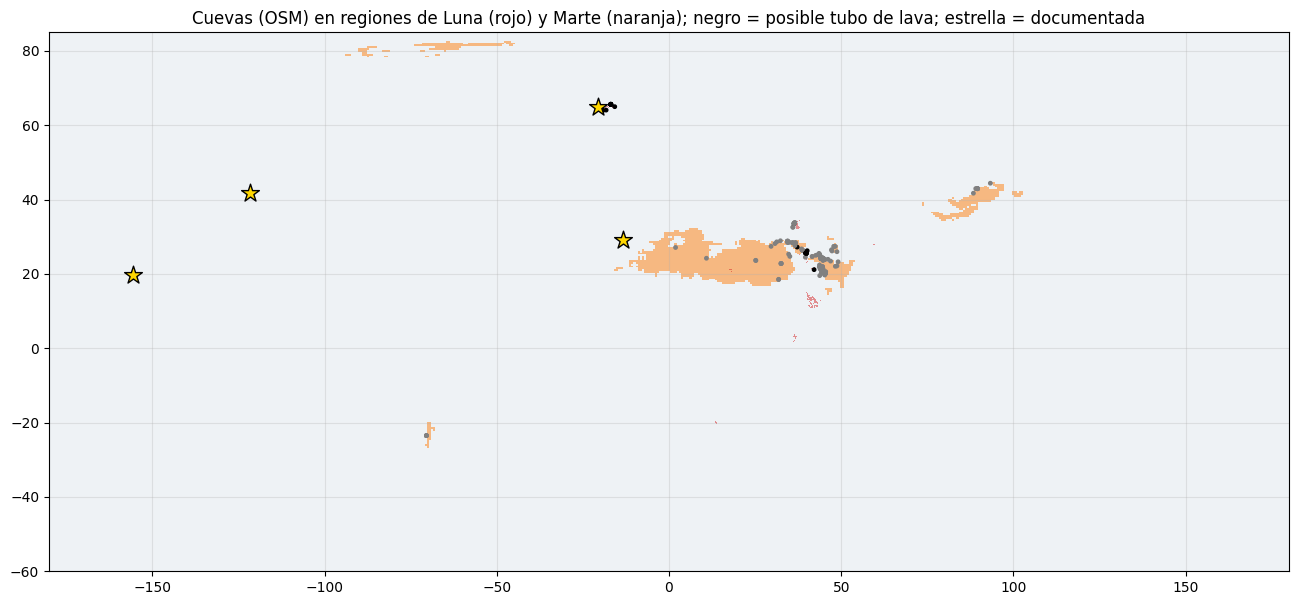

In [8]:
resumen = (osm[osm.region_id.notna()].groupby("region_id")
           .agg(entradas_cueva=("osm_id", "size"), posibles_tubos_lava=("posible_tubo_lava", "sum"),
                ejemplos=("nombre", lambda s: "; ".join(s.dropna().unique()[:3]))).reset_index())
resumen = regiones[["region_id", "cuerpo", "perfil", "rango", "region"]].merge(resumen, on="region_id", how="left")
resumen[["entradas_cueva", "posibles_tubos_lava"]] = resumen[["entradas_cueva", "posibles_tubos_lava"]].fillna(0).astype(int)
resumen["ejemplos"] = resumen.ejemplos.fillna("")
resumen.to_csv(f"{RES}/cuevas_por_region.csv", index=False)
print("Regiones con al menos una entrada de cueva:")
print(resumen.groupby("cuerpo").apply(lambda d: f"{(d.entradas_cueva > 0).sum()} de {len(d)}").to_string())
display(resumen.sort_values(["cuerpo", "posibles_tubos_lava", "entradas_cueva"], ascending=[True, False, False]).head(25))

fig, ax = plt.subplots(figsize=(16, 7))
ax.set_facecolor("#eef2f5")
for r in regiones.itertuples():
    gs = [r.geom] if r.geom.geom_type == "Polygon" else list(r.geom.geoms)
    for g in gs:
        x, y = g.exterior.xy
        ax.fill(x, y, color="tab:red" if r.cuerpo == "luna" else "tab:orange", alpha=0.5, lw=0)
o = osm[osm.region_id.notna()]
ax.scatter(o.lon, o.lat, s=6, c=np.where(o.posible_tubo_lava, "black", "grey"), zorder=3)
ax.scatter(CUEVAS_REF.lon, CUEVAS_REF.lat, marker="*", s=180, c="gold", edgecolors="k", zorder=4)
ax.set_xlim(-180, 180); ax.set_ylim(-60, 85); ax.grid(alpha=0.3)
ax.set_title("Cuevas (OSM) en regiones de Luna (rojo) y Marte (naranja); negro = posible tubo de lava; estrella = documentada")
plt.show()

## 8. Capa para la web → `06_web/cuevas_v0/`
`cuevas.geojson`: puntos de las cuevas documentadas (`origen = literatura`) y de las entradas de OSM asociadas a una región
(`origen = openstreetmap`). Se añade el bloque `capas.cuevas` a `06_web/manifest.json`.

In [9]:
def limpio(v):
    if isinstance(v, (float, np.floating)): return None if np.isnan(v) else round(float(v), 4)
    if isinstance(v, (np.integer,)): return int(v)
    if isinstance(v, (np.bool_,)): return bool(v)
    return v

feats = []
for c in CUEVAS_REF.itertuples():
    v, cl = litologia_punto(c.lat, c.lon)
    props = {"origen": "literatura", "nombre": c.nombre, "analogo_de": c.analogo_de, "motivo": c.motivo,
             "fuente": c.fuente, "fuente_2": c.fuente_2 or None, "glim_clase": cl, "glim_volcanica_pct": v, "posible_tubo_lava": True}
    feats.append({"type": "Feature", "geometry": {"type": "Point", "coordinates": [c.lon, c.lat]},
                  "properties": {k: limpio(x) for k, x in props.items()}})
for c in osm[osm.region_id.notna()].itertuples():
    props = {"origen": "openstreetmap", "osm_id": c.osm_id, "nombre": c.nombre, "region_id": c.region_id, "cuerpo": c.cuerpo,
             "dist_region_km": c.dist_region_km, "glim_clase": c.glim_clase, "glim_volcanica_pct": c.glim_volcanica_pct,
             "posible_tubo_lava": bool(c.posible_tubo_lava), "url": f"https://www.openstreetmap.org/{c.osm_id}"}
    feats.append({"type": "Feature", "geometry": {"type": "Point", "coordinates": [round(c.lon, 5), round(c.lat, 5)]},
                  "properties": {k: limpio(x) for k, x in props.items()}})
with open(f"{WEB}/cuevas.geojson", "w", encoding="utf-8") as f:
    json.dump({"type": "FeatureCollection", "features": feats,
               "metadata": {"version": VERSION, "atribucion": "© colaboradores de OpenStreetMap (ODbL)", "crs": "EPSG:4326"}},
              f, ensure_ascii=False, allow_nan=False)

registro = {"version": VERSION, "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
            "metodo": {"osm": 'nwr["natural"="cave_entrance"] por caja de región + 25 km (Overpass API)',
                       "posible_tubo_lava": "celda GLiM >= 50 % volcánica o nombre/etiquetas con lava, tubo, hellir…",
                       "region": f"dentro del polígono o a <= {MARGEN_KM} km"},
            "recuentos": {"entradas_osm": int(len(osm)), "en_regiones": int(osm.region_id.notna().sum()),
                          "posibles_tubos_lava_en_regiones": int(osm[osm.region_id.notna()].posible_tubo_lava.sum())},
            "validacion": validacion.to_dict("records"),
            "limitaciones": ["cobertura de OpenStreetMap desigual por país: los recuentos son mínimos",
                             "una entrada en roca volcánica no garantiza que sea un tubo de lava",
                             "coordenadas de las cuevas documentadas aproximadas"]}
json.dump(registro, open(f"{RES}/registro_{VERSION}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, default=str)

manifest = {"version": VERSION, "archivo": "cuevas.geojson", "crs": "EPSG:4326",
            "descripcion": "Cuevas análogas documentadas y entradas de cueva de OpenStreetMap en las regiones candidatas de Luna y Marte",
            "description_en": "Documented analogue caves and OpenStreetMap cave entrances in the Moon and Mars candidate regions",
            "atribucion": "© OpenStreetMap contributors (ODbL)", "recuentos": registro["recuentos"],
            "campos": {"origen": "literatura | openstreetmap", "posible_tubo_lava": "roca volcánica (GLiM) o nombre que lo indica",
                       "region_id": "id de la región en regiones.geojson del cuerpo correspondiente"}}
json.dump(manifest, open(f"{WEB}/manifest.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
entrada.setdefault("capas", {})["cuevas"] = {"version": VERSION, "carpeta": VERSION, "archivo": f"{VERSION}/cuevas.geojson",
                                             "manifest": f"{VERSION}/manifest.json"}
json.dump(entrada, open(f"{BASE}/06_web/manifest.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print(f"cuevas.geojson: {len(feats)} puntos ({os.path.getsize(f'{WEB}/cuevas.geojson')/1e3:.0f} KB)")
print("capas en el manifest común:", list(entrada["capas"]))

cuevas.geojson: 199 puntos (78 KB)
capas en el manifest común: ['cuevas']


## 9. Conclusiones
*Rellenar tras la primera ejecución: ¿recoge OSM las cuevas documentadas? ¿Qué regiones tienen posibles tubos de lava?*